# Ventes : quels produits rapportent le plus ?

**Problème :** Analyser le chiffre d'affaires par produit, ville et canal. Anomalies : doublon, ville manquante, texte mal formaté.

Les données sont synthétiques. Exécute les cellules dans l'ordre. Le fichier `donnees.xlsx` doit rester dans le même dossier que ce notebook.

## Étape 1 — Lire et explorer les données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_excel("donnees.xlsx", sheet_name="donnees")
print("Dimensions :", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=1))


Dimensions : (31, 8)


,commande_id,date,ville,produit,quantite,prix_unitaire,canal,montant
0,V001,2026-01-01,Tanger,Casque,4,450,Magasin,1800
1,V002,2026-01-03,Marrakech,Clavier,1,250,En ligne,250
2,V003,2026-01-05,Tanger,Clavier,4,250,En ligne,1000
3,V004,2026-01-07,NaN,Écran,4,1600,Magasin,6400
4,V005,2026-01-09,Casablanca,Souris,4,120,Magasin,480


,commande_id,date,ville,produit,quantite,prix_unitaire,canal,montant
27,V028,2026-02-24,Casablanca,Casque,3,450,En ligne,1350
3,V004,2026-01-07,NaN,Écran,4,1600,Magasin,6400
19,V020,2026-02-08,Casablanca,Souris,2,120,En ligne,240
23,V024,2026-02-16,Rabat,Casque,2,450,Magasin,900
22,V023,2026-02-14,Rabat,Écran,2,1600,Magasin,3200


## Étape 2 — Comprendre la structure

In [2]:
df.info()
display(df.describe(include="all").T)
print("Colonnes :", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   commande_id    31 non-null     str           
 1   date           31 non-null     datetime64[us]
 2   ville          29 non-null     str           
 3   produit        31 non-null     str           
 4   quantite       31 non-null     int64         
 5   prix_unitaire  31 non-null     int64         
 6   canal          31 non-null     str           
 7   montant        31 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(4)
memory usage: 2.1 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
commande_id,31,30,V005,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,31,NaN,NaN,NaN,2026-01-29 07:44:30.967742,2026-01-01 00:00:00,2026-01-14 00:00:00,2026-01-29 00:00:00,2026-02-13 00:00:00,2026-02-28 00:00:00,NaN
ville,29,4,Casablanca,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
produit,31,5,Casque,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantite,31.0,NaN,NaN,NaN,2.580645,1.0,2.0,2.0,4.0,4.0,1.118755
prix_unitaire,31.0,NaN,NaN,NaN,664.193548,120.0,250.0,450.0,1600.0,1600.0,619.746046
canal,31,2,Magasin,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
montant,31.0,NaN,NaN,NaN,1667.741935,120.0,480.0,900.0,1700.0,6400.0,1876.371871


Colonnes : ['commande_id', 'date', 'ville', 'produit', 'quantite', 'prix_unitaire', 'canal', 'montant']


## Étape 3 — Détecter les anomalies

In [3]:
print("Valeurs manquantes :")
display(df.isna().sum())
print("Lignes dupliquées :", df.duplicated().sum())
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\\n{col} :", df[col].dropna().astype(str).unique()[:15])


Valeurs manquantes :


commande_id      0
date             0
ville            2
produit          0
quantite         0
prix_unitaire    0
canal            0
montant          0
dtype: int64

Lignes dupliquées : 1
\ncommande_id : <StringArray>
['V001', 'V002', 'V003', 'V004', 'V005', 'V006', 'V007', 'V008', 'V009',
 'V010', 'V011', 'V012', 'V013', 'V014', 'V015']
Length: 15, dtype: str
\nville : <StringArray>
['Tanger', 'Marrakech', 'Casablanca', 'Rabat']
Length: 4, dtype: str
\nproduit : <StringArray>
['Casque', 'Clavier', 'Écran', 'Souris', ' souris ']
Length: 5, dtype: str
\ncanal : <StringArray>
['Magasin', 'En ligne']
Length: 2, dtype: str


## Étape 4 — Nettoyer les données

On conserve `df` intact et on travaille sur une copie `df_clean`. Adapte les règles selon le problème métier.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

# Nettoyage simple des espaces dans les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

df_clean["ville"] = df_clean["ville"].fillna("Inconnue").str.title()
df_clean["produit"] = df_clean["produit"].str.title()
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.head())

Dimensions après nettoyage : (30, 8)


,commande_id,date,ville,produit,quantite,prix_unitaire,canal,montant
0,V001,2026-01-01,Tanger,Casque,4,450,Magasin,1800
1,V002,2026-01-03,Marrakech,Clavier,1,250,En ligne,250
2,V003,2026-01-05,Tanger,Clavier,4,250,En ligne,1000
3,V004,2026-01-07,Inconnue,Écran,4,1600,Magasin,6400
4,V005,2026-01-09,Casablanca,Souris,4,120,Magasin,480


## Étape 5 — Analyse avec Pandas et calculs NumPy

In [5]:
# Recalcul du montant à partir de la quantité et du prix
df_clean["quantite"] = pd.to_numeric(df_clean["quantite"], errors="coerce")
df_clean["prix_unitaire"] = pd.to_numeric(df_clean["prix_unitaire"], errors="coerce")
df_clean = df_clean[(df_clean["quantite"] > 0) & (df_clean["prix_unitaire"] > 0)].copy()
df_clean["montant_calcule"] = df_clean["quantite"] * df_clean["prix_unitaire"]
display(df_clean.groupby("produit")["montant_calcule"].agg(["sum","mean","count"]).sort_values("sum", ascending=False))
print("CA total :", np.sum(df_clean["montant_calcule"]))


,sum,mean,count
produit,,,
Écran,33600,4200.000000,8
Casque,10350,1293.750000,8
Clavier,3750,535.714286,7
Souris,3520,502.857143,7


CA total : 51220


## Étape 6 — Visualisation avec Matplotlib

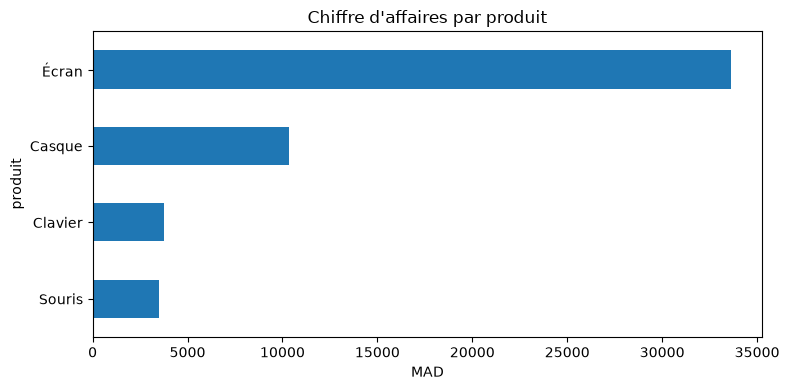

In [6]:
df_clean.groupby("produit")["montant_calcule"].sum().sort_values().plot(kind="barh", figsize=(8,4))
plt.title("Chiffre d'affaires par produit")
plt.xlabel("MAD")
plt.tight_layout()
plt.show()


## Exporter le résultat nettoyé

In [7]:
df_clean.to_csv("donnees_nettoyees.csv", index=False, encoding="utf-8-sig")
df_clean.to_excel("donnees_nettoyees.xlsx", index=False)
print("Export terminé.")


Export terminé.
